# 03 — Statistical Analysis (FD001)

**Project:** Predictive Intelligence · **Phase 2**

## Objective

Notebook 02 showed wear in pictures. This notebook puts numbers on four questions whose answers shape how we prepare the data in Phase 4:

1. What does the sensor noise on a healthy engine look like?
2. How much do engines differ from each other *before* any wear?
3. How consistently does each sensor trend over an engine's life?
4. How early before failure can wear be told apart from noise?
5. Do the training and test engines come from the same population?

No model is trained. Only the training set is used, except in section 6 where early test readings are compared with early training readings (no test labels are used).

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src.data.cmapss import SENSOR_COLUMNS, SENSOR_INFO, add_training_rul, load_subset
from src.visualization import theme

theme.apply_theme()
pd.set_option("display.max_columns", 30)

train, test, _ = load_subset("FD001")
train_labelled = add_training_rul(train)
varying_sensors = [name for name in SENSOR_COLUMNS if train[name].nunique() > 2]


def sensor_label(name: str) -> str:
    return f"{name.replace('sensor_', 'S')} · {SENSOR_INFO[name][0]}"

## 2. Noise on a healthy engine

**Why look at this.** Every later step has to separate a real change from random flicker. To do that we need to know how big the flicker is and what shape it has.

**Method.** We treat each engine's first 30 cycles as its healthy period. For each engine we subtract its own healthy average from those readings. What is left (the *residual*) is the cycle-to-cycle noise, with differences between engines removed.

Three numbers describe the shape of the noise:

- **Skewness** — is the noise lopsided? 0 means symmetric.
- **Excess kurtosis** — are extreme values more common than in a bell curve? 0 means bell-curve-like; positive means heavier tails.
- **Normality test p-value** (D'Agostino–Pearson) — a formal check of "could this be a bell curve?". A small p-value (below 0.05) is evidence against it. With 3,000 readings the test is very sensitive, so it should be read alongside the first two numbers, not instead of them.

The 30-cycle choice is a judgement: long enough to average out noise, short enough that little wear has occurred (the shortest-lived engine still has 98 cycles left at cycle 30).

In [2]:
HEALTHY_CYCLES = 30

healthy = train_labelled[train_labelled["cycle"] <= HEALTHY_CYCLES]
engine_baseline = healthy.groupby("engine_id")[varying_sensors].mean()

# Residual = reading minus that engine's own healthy average.
healthy_residual = healthy[varying_sensors] - engine_baseline.loc[healthy["engine_id"]].to_numpy()
noise_sd = healthy_residual.std()

noise_shape = pd.DataFrame({
    "symbol": [SENSOR_INFO[s][0] for s in varying_sensors],
    "noise sd": noise_sd,
    "skewness": healthy_residual.skew(),
    "excess kurtosis": healthy_residual.kurt(),
    "normality p-value": [stats.normaltest(healthy_residual[s]).pvalue for s in varying_sensors],
    "distinct values": healthy[varying_sensors].nunique(),
}, index=varying_sensors)
noise_shape.round(3)

,symbol,noise sd,skewness,excess kurtosis,normality p-value,distinct values
sensor_2,T24,0.297,-0.012,0.034,0.881,209
sensor_3,T30,3.958,0.002,0.093,0.580,1476
sensor_4,T50,3.898,0.038,0.347,0.002,1667
sensor_7,P30,0.400,-0.015,0.112,0.438,310
sensor_8,Nf,0.031,0.001,0.050,0.841,33
sensor_9,Nc,4.164,-0.033,-0.052,0.648,1965
sensor_11,Ps30,0.100,-0.027,0.125,0.327,97
sensor_12,phi,0.299,-0.066,-0.101,0.173,257
sensor_13,NRf,0.029,0.052,0.038,0.456,31
sensor_14,NRc,3.062,0.057,-0.087,0.271,1899


Largest correlation between the noise of two different sensors: 0.059


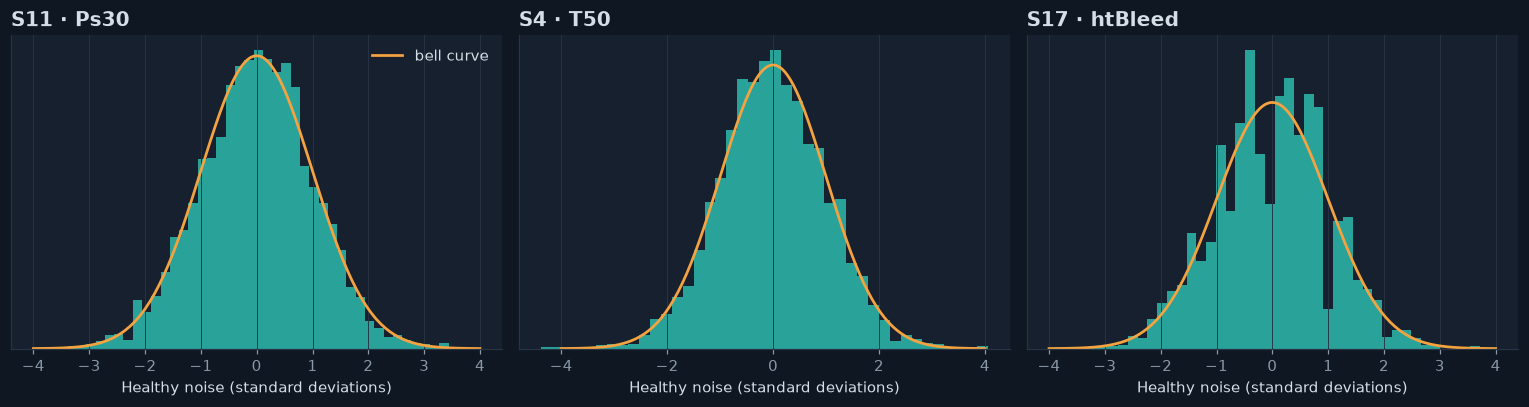

In [3]:
residual_correlation = healthy_residual.corr()
off_diagonal = residual_correlation.where(~np.eye(len(varying_sensors), dtype=bool))
print(f"Largest correlation between the noise of two different sensors: {off_diagonal.abs().max().max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, sensor in zip(axes, ["sensor_11", "sensor_4", "sensor_17"]):
    standardised = healthy_residual[sensor] / noise_sd[sensor]
    ax.hist(standardised, bins=41, density=True, color=theme.TEAL, alpha=0.8)
    grid = np.linspace(-4, 4, 200)
    ax.plot(grid, stats.norm.pdf(grid), color=theme.AMBER, linewidth=1.8, label="bell curve")
    ax.set_title(sensor_label(sensor))
    ax.set_xlabel("Healthy noise (standard deviations)")
    ax.set_yticks([])
axes[0].legend()
fig.tight_layout()
plt.show()

**Findings.**

- **The noise is close to a bell curve.** Skewness and excess kurtosis are near zero for every sensor, and the normality test raises a flag for only one of the fourteen (S4, with slightly heavy tails). This is what we would expect from simulated measurement noise.
- **Some sensors are coarse.** S17 (bleed enthalpy) is recorded as whole numbers and takes only 9 distinct values in the healthy period, visible as the comb-like histogram. S8 and S13 have about 30 distinct values. These carry real trend information, but in coarse steps.
- **Noise is independent between sensors.** The largest correlation between the noise of any two sensors is about 0.06. So when two sensors move *together*, that is wear, not noise.

**Why it matters.** Independent noise can be averaged away: combining 12 sensors should shrink the noise by a factor of about √12 ≈ 3.5. Section 5 tests this. Near-Gaussian noise also means standard scaling (subtract mean, divide by standard deviation) is a reasonable choice in Phase 4, and no outlier treatment is needed.

## 3. How different are engines before any wear?

The NASA paper says each engine starts with its own amount of manufacturing variation and initial wear. If that variation is large, then a reading that is normal for one engine could look like wear on another.

**Method.** In the healthy period, total variation in a sensor has two sources: noise within an engine, and differences between engines' average levels. We measure what share of the total comes from differences *between* engines.

- Near 0%: all engines start at the same level; only noise differs.
- Near 100%: each engine has its own level, and noise is small in comparison.

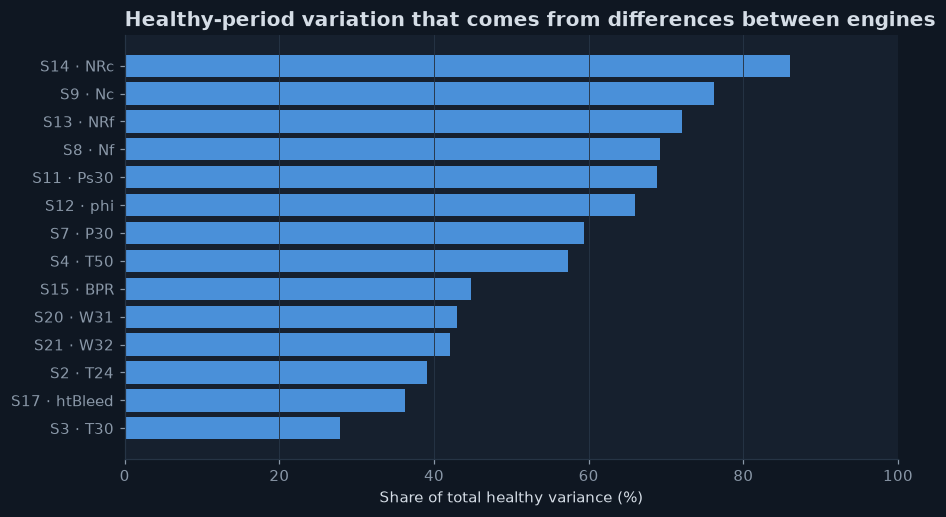

,sensor_3,sensor_17,sensor_2,sensor_21,sensor_20,sensor_15,sensor_4,sensor_7,sensor_12,sensor_11,sensor_8,sensor_13,sensor_9,sensor_14
between-engine share (%),27.8,36.2,39.1,42.1,43.0,44.8,57.4,59.5,65.9,68.9,69.3,72.0,76.2,86.0


In [4]:
between_engine_share = (engine_baseline.var() / healthy[varying_sensors].var()).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh([sensor_label(s) for s in between_engine_share.index], between_engine_share * 100, color=theme.BLUE)
ax.set_title("Healthy-period variation that comes from differences between engines")
ax.set_xlabel("Share of total healthy variance (%)")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

(between_engine_share * 100).round(1).to_frame("between-engine share (%)").T

**Findings.**

- Engines are far from identical when new. Between 28% and 86% of healthy-period variation is engine-to-engine difference, depending on the sensor.
- The core speeds (S14, S9) are the most engine-specific, followed by the fan speeds and S11. This helps explain why S9 and S14 looked so irregular in notebook 02: much of what they show is *which engine this is*, not *how worn it is*.

**Why it matters.** A model that sees only raw readings has to work out each engine's personal starting level by itself. Giving it that level directly, for example "change since this engine's own first cycles", may help. This is legitimate for the test set too, because test engines are also recorded from cycle 1, so their early readings are available. It goes to Phase 4 as an option to test, not a decision.

## 4. How consistently does each sensor trend?

A good wear indicator should move in one direction over an engine's life, and in the *same* direction on every engine.

**Method.** For each engine and each sensor we compute the Spearman correlation between the reading and the cycle number (Spearman, as in notebook 01, because the drift is curved). Then we summarise across the 100 engines: the typical strength, and the share of engines that agree on the direction.

In [5]:
per_engine_trend = train_labelled.groupby("engine_id")[varying_sensors].apply(
    lambda engine: engine.corrwith(train_labelled.loc[engine.index, "cycle"], method="spearman")
)

trend_summary = pd.DataFrame({
    "symbol": [SENSOR_INFO[s][0] for s in varying_sensors],
    "median trend": per_engine_trend.median(),
    "weakest engine": per_engine_trend.abs().min(),
    "engines agreeing on direction (%)": (np.sign(per_engine_trend) == np.sign(per_engine_trend.median())).mean() * 100,
}).sort_values("median trend", key=abs, ascending=False)
trend_summary.round(2)

,symbol,median trend,weakest engine,engines agreeing on direction (%)
sensor_11,Ps30,0.82,0.65,100.0
sensor_12,phi,-0.81,0.61,100.0
sensor_4,T50,0.78,0.61,100.0
sensor_7,P30,-0.77,0.54,100.0
sensor_8,Nf,0.77,0.12,100.0
sensor_13,NRf,0.76,0.10,100.0
sensor_9,Nc,0.74,0.02,71.0
sensor_15,BPR,0.72,0.58,100.0
sensor_21,W32,-0.71,0.53,100.0
sensor_20,W31,-0.71,0.58,100.0


**Findings.**

- **Twelve sensors agree on direction in 100% of engines.** Their typical trend strength is between 0.64 and 0.82. The strongest are S11 (Ps30), S12 (phi), S4 (T50) and S7 (P30).
- **S9 and S14 do not.** Only 71% and 60% of engines agree on direction. Their median looks respectable, but that hides engines trending the other way. This confirms notebook 02 with a number.
- The fan speeds S8 and S13 agree on direction everywhere but are very weak on a few engines (weakest about 0.1), probably because they are recorded in coarse steps.
- Even the best sensor has a trend strength well below 1 on a single engine. That is the noise and the long flat period, not a lack of signal.

## 5. How early can wear be detected?

This is the most important question in the notebook, because it tells us how far ahead a prediction can honestly be made.

**Method.**

1. For every reading, compute its distance from that engine's own healthy average, in units of that sensor's healthy noise. Call this the **drift score**. A drift score of 0 means "exactly this engine's normal"; a score of 2 means "two noise-widths away from normal".
2. Group readings by how many cycles remain before failure (in bands of 10) and average the drift score across the fleet.
3. Find how many cycles before failure the average drift first reaches 1 and 2 noise-widths.

Readings from the healthy period itself are excluded, since they define the baseline. Bands with fewer than 30 engines are left out so that a few long-lived engines cannot dominate.

In [6]:
drift = (train_labelled[varying_sensors] - engine_baseline.loc[train_labelled["engine_id"]].to_numpy()) / noise_sd
drift[["engine_id", "cycle", "rul"]] = train_labelled[["engine_id", "cycle", "rul"]]
after_baseline = drift[drift["cycle"] > HEALTHY_CYCLES].copy()
after_baseline["rul_band"] = (after_baseline["rul"] // 10) * 10

engines_per_band = after_baseline.groupby("rul_band")["engine_id"].nunique()
reliable_bands = engines_per_band.index[engines_per_band >= 30]
mean_drift = after_baseline.groupby("rul_band")[varying_sensors].mean().loc[reliable_bands]


def earliest_band_reaching(series: pd.Series, level: float) -> int:
    # Largest "cycles remaining" band from which the average drift stays at or above the level.
    below = series.index[series.abs() < level]
    return int(below.min()) if len(below) else int(series.index.max())


detection = pd.DataFrame({
    "symbol": [SENSOR_INFO[s][0] for s in varying_sensors],
    "drift at failure": mean_drift.loc[0],
    "reaches 1 noise-width at (cycles left)": [earliest_band_reaching(mean_drift[s], 1) for s in varying_sensors],
    "reaches 2 noise-widths at (cycles left)": [earliest_band_reaching(mean_drift[s], 2) for s in varying_sensors],
}, index=varying_sensors)
detection.round(2)

,symbol,drift at failure,reaches 1 noise-width at (cycles left),reaches 2 noise-widths at (cycles left)
sensor_2,T24,4.09,70,40
sensor_3,T30,3.67,70,40
sensor_4,T50,6.30,100,60
sensor_7,P30,-5.80,90,60
sensor_8,Nf,5.21,80,50
sensor_9,Nc,9.48,100,70
sensor_11,Ps30,7.45,110,70
sensor_12,phi,-6.62,100,60
sensor_13,NRf,5.60,90,50
sensor_14,NRc,9.07,100,70


### Combining sensors into one health indicator

Section 2 predicted that averaging sensors would shrink the noise. We test that by building a simple **combined drift score**: the average drift of the twelve consistent sensors, with the falling sensors flipped so that "up" always means "more worn". S9 and S14 are left out because their direction is not consistent.

This is a diagnostic tool for understanding the data. It is not the model.

Noise of the combined indicator: 0.303 of a single sensor's noise
Expected if noise were fully independent (1/sqrt(12)): 0.289


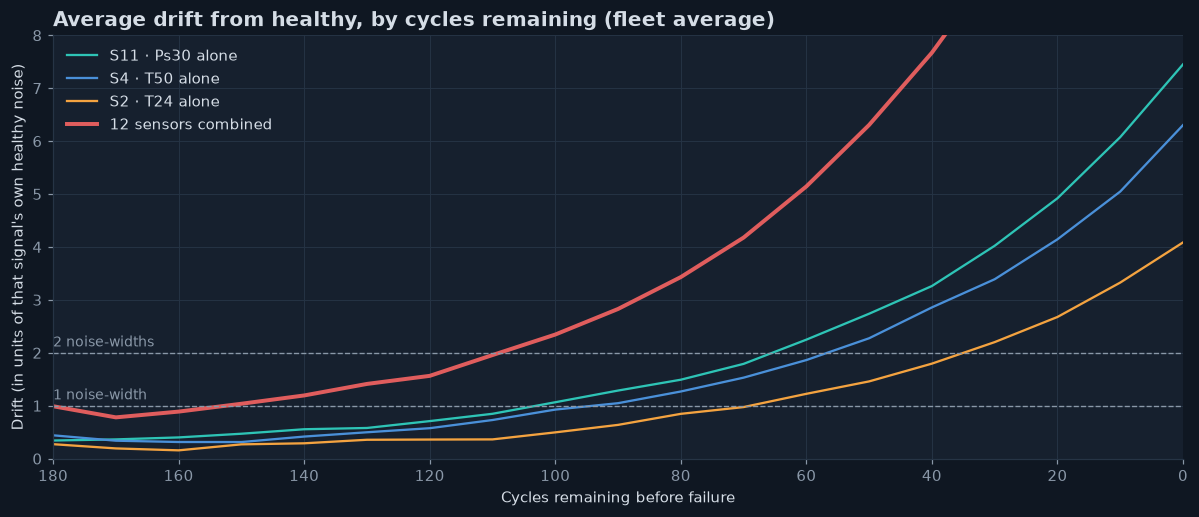

In [7]:
consistent_sensors = [s for s in varying_sensors if s not in ("sensor_9", "sensor_14")]
direction = np.sign(mean_drift.loc[0, consistent_sensors])   # +1 if the sensor rises with wear, -1 if it falls

combined = (drift[consistent_sensors] * direction).mean(axis=1)
combined_noise_sd = combined[drift["cycle"] <= HEALTHY_CYCLES].std()
drift["combined_score"] = combined / combined_noise_sd

print(f"Noise of the combined indicator: {combined_noise_sd:.3f} of a single sensor's noise")
print(f"Expected if noise were fully independent (1/sqrt(12)): {1 / np.sqrt(len(consistent_sensors)):.3f}")

after_baseline = drift[drift["cycle"] > HEALTHY_CYCLES].copy()
after_baseline["rul_band"] = (after_baseline["rul"] // 10) * 10
combined_by_band = after_baseline.groupby("rul_band")["combined_score"].mean().loc[reliable_bands]

fig, ax = plt.subplots(figsize=(11, 4.8))
for sensor in ["sensor_11", "sensor_4", "sensor_2"]:
    ax.plot(mean_drift.index, mean_drift[sensor].abs(), linewidth=1.5, label=f"{sensor_label(sensor)} alone")
ax.plot(combined_by_band.index, combined_by_band, color=theme.RED, linewidth=2.6, label="12 sensors combined")
for level in (1, 2):
    ax.axhline(level, color=theme.MUTED, linestyle="--", linewidth=0.9)
    ax.text(mean_drift.index.max(), level + 0.12, f"{level} noise-width{'s' if level > 1 else ''}",
            color=theme.MUTED, ha="left", fontsize=9)
ax.set_xlim(mean_drift.index.max(), 0)
ax.set_ylim(0, 8)
ax.set_title("Average drift from healthy, by cycles remaining (fleet average)")
ax.set_xlabel("Cycles remaining before failure")
ax.set_ylabel("Drift (in units of that signal's own healthy noise)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The chart above is a fleet *average*. A maintainer cares about individual engines, so the next table asks: at a given number of cycles before failure, what share of engines already show a combined score above 1 and above 2?

In [8]:
rows = []
for cycles_left in [150, 125, 100, 75, 50]:
    in_band = after_baseline[after_baseline["rul"].between(cycles_left, cycles_left + 9)]
    engine_score = in_band.groupby("engine_id")["combined_score"].mean()
    rows.append({
        "cycles remaining": f"{cycles_left}-{cycles_left + 9}",
        "engines observed": len(engine_score),
        "share with score above 1 (%)": (engine_score > 1).mean() * 100,
        "share with score above 2 (%)": (engine_score > 2).mean() * 100,
    })
pd.DataFrame(rows).set_index("cycles remaining").round(0)

,engines observed,share with score above 1 (%),share with score above 2 (%)
cycles remaining,,,
150-159,71,42.0,13.0
125-134,89,61.0,20.0
100-109,99,82.0,47.0
75-84,100,98.0,86.0
50-59,100,100.0,100.0


**Findings.**

- **A single sensor shows wear late.** On average, individual sensors drift one noise-width away from healthy only in roughly the last 70 to 110 cycles, and two noise-widths in the last 40 to 70. Earlier than that, one sensor's reading is within its normal flicker.
- **Averaging works as predicted.** The combined indicator's noise is 0.30 of a single sensor's, close to the theoretical 0.29 for fully independent noise.
- **Combining sensors buys lead time.** The combined score crosses the same thresholds noticeably earlier than any single sensor, as the red line shows.
- **Per engine, the picture is gradual.** With 100 to 109 cycles left, about 8 in 10 engines show a combined score above 1 but only about half are above 2. With 125 to 134 left, about 6 in 10 are above 1. By 75 cycles left nearly every engine is clearly off its baseline.

**What this means for the project.**

- Beyond roughly 125–150 cycles before failure, the sensors contain little evidence about *how much* life is left. Asking a model to tell 200 remaining cycles from 300 is asking it to read noise.
- This is the statistical argument for **capping the RUL label**: treating everything above some value as simply "healthy". The evidence here points to a cap somewhere around 100–150 cycles. The exact value is a modelling choice to be tested on validation engines in Phase 4, not read off this chart.
- It also sets an honest expectation for the final system: predictions for engines with long remaining life will carry wide uncertainty, and the assistant must say so.

**Caveats.** The drift score uses each engine's first 30 cycles as "healthy", which assumes little wear by then. The thresholds 1 and 2 are illustrative, not safety limits.

## 6. Do training and test engines come from the same population?

A model learned on the training engines is only trustworthy on the test engines if both behave alike. We compare them where they are comparable: the first 30 cycles, when engines in both sets are still healthy. No test labels are involved.

**Method.** For each sensor we have 100 training-engine baselines and 100 test-engine baselines. The **two-sample Kolmogorov–Smirnov (KS) test** asks whether two sets of numbers could come from the same distribution. Its statistic is the largest gap between the two cumulative distributions (0 = identical, 1 = no overlap). A p-value below 0.05 would be evidence that the sets differ.

We compare per-engine averages rather than individual readings. Readings from the same engine share that engine's offset (section 3), so treating all 3,000 readings as independent would make the test far too confident.

Running 14 tests means one or two may dip below 0.05 by chance alone, so we also apply a **Bonferroni correction**: with 14 tests, a result counts only if p is below 0.05 / 14 ≈ 0.0036.

In [9]:
test_baseline = test[test["cycle"] <= HEALTHY_CYCLES].groupby("engine_id")[varying_sensors].mean()

ks_rows = []
for sensor in varying_sensors:
    result = stats.ks_2samp(engine_baseline[sensor], test_baseline[sensor])
    ks_rows.append({
        "sensor": sensor,
        "symbol": SENSOR_INFO[sensor][0],
        "train mean": engine_baseline[sensor].mean(),
        "test mean": test_baseline[sensor].mean(),
        "KS statistic": result.statistic,
        "p-value": result.pvalue,
    })
ks_table = pd.DataFrame(ks_rows).set_index("sensor")

bonferroni_level = 0.05 / len(varying_sensors)
print(f"Sensors with p < 0.05: {(ks_table['p-value'] < 0.05).sum()} of {len(ks_table)}")
print(f"Sensors with p < {bonferroni_level:.4f} (Bonferroni): {(ks_table['p-value'] < bonferroni_level).sum()}")
ks_table.round(3)

Sensors with p < 0.05: 0 of 14
Sensors with p < 0.0036 (Bonferroni): 0


,symbol,train mean,test mean,KS statistic,p-value
sensor,,,,,
sensor_2,T24,642.383,642.355,0.13,0.368
sensor_3,T30,1586.898,1586.688,0.15,0.211
sensor_4,T50,1402.831,1402.180,0.13,0.368
sensor_7,P30,553.948,554.002,0.09,0.815
sensor_8,Nf,2388.059,2388.055,0.10,0.702
sensor_9,Nc,9056.062,9055.043,0.13,0.368
sensor_11,Ps30,47.356,47.339,0.13,0.368
sensor_12,phi,521.905,521.952,0.11,0.583
sensor_13,NRf,2388.057,2388.055,0.13,0.368


**Findings.**

- No sensor shows a detectable difference between training and test engines. Every p-value is above 0.2, so none passes even the uncorrected 0.05 level, let alone the Bonferroni level.
- The average healthy levels in the two sets agree closely in the table.
- So, as far as early-life behaviour can show, the test engines are drawn from the same fleet as the training engines. Together with the matching total lifetimes found in notebook 01, there is no sign of a shift between the two sets.

**Caveat.** "No detectable difference" with 100 engines per set means any difference is small, not that it is exactly zero. This check also covers only the healthy period.

## 7. Conclusions

| Question | Answer for FD001 |
|---|---|
| Shape of healthy noise | Close to a bell curve; independent between sensors |
| Engine-to-engine differences | Large: 28–86% of healthy variation, highest for core and fan speeds |
| Consistent trend | 12 sensors trend the same way on every engine; S9 and S14 do not |
| Detectability of wear | Single sensors: roughly the last 70–110 cycles. Combined: earlier, but weak beyond about 125–150 |
| Train versus test | No detectable difference in healthy-period behaviour (all KS p-values above 0.2) |

**Limitations.** One simulated subset, one fault mode, one flight condition. The healthy window, the drift thresholds and the choice of twelve sensors are analysis choices; different reasonable choices would shift the numbers somewhat but not the overall picture.

## 8. Questions handed to Phase 4

1. **RUL cap:** test candidate caps in the 100–150 range on validation engines.
2. **Sensor selection:** drop the constant columns; test whether S9 and S14 help or hurt.
3. **Engine baseline:** test features expressed as change from each engine's own early readings.
4. **Scaling:** standard scaling is justified by the near-Gaussian noise; fit it on training engines only.
5. **Window length:** long enough to average noise, short enough for test engines with 31 cycles of history.